In [4]:
import pandas as pd

# Load the dataset
df = pd.read_csv("Week10_Big Data/week10_students.csv")

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display correlation with score
print("\nCorrelation with Score:")
print(df[["quiz_avg", "assignments_avg", "attendance_pct", "score"]].corr()["score"])

Dataset Shape: (150, 9)

Correlation with Score:
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
score              1.000000
Name: score, dtype: float64


In [5]:
from sklearn.model_selection import train_test_split

# Select the input features
X = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

# Select the target variable
y = df["score"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Display the results
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (112, 3)
Testing data: (38, 3)


In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display model coefficients and intercept
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

# Make predictions on test data
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("R² Score:", r2)

Coefficients: [0.57897954 0.364775   0.1133959 ]
Intercept: -4.428213336154187
Mean Absolute Error: 3.3291993077316504
R² Score: 0.8866487356612142


In [7]:
# Predict score for a new student
new_student = pd.DataFrame({
    "quiz_avg": [75],
    "assignments_avg": [80],
    "attendance_pct": [90]
})

prediction = model.predict(new_student)

print("Predicted score for new student:", prediction[0])

# Predict score for an invented student
my_student = pd.DataFrame({
    "quiz_avg": [85],
    "assignments_avg": [90],
    "attendance_pct": [95]
})

my_prediction = model.predict(my_student)

print("Predicted score for my invented student:", my_prediction[0])

Predicted score for new student: 78.38288256100206
Predicted score for my invented student: 88.38740739746942


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Create pass/fail target
y_pass = (df["score"] >= 50).astype(int)

# Split the data
X_train_pass, X_test_pass, y_train_pass, y_test_pass = train_test_split(
    X, y_pass, test_size=0.25, random_state=42
)

# Create and train logistic regression model
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_pass, y_train_pass)

# Make predictions
y_pass_pred = log_model.predict(X_test_pass)

# Calculate accuracy
accuracy = accuracy_score(y_test_pass, y_pass_pred)

print("Logistic Regression Accuracy:", accuracy)

# Calculate baseline accuracy (predict everyone passes)
baseline = (y_test_pass == 1).mean()

print("All-Pass Baseline Accuracy:", baseline)

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_pass, y_pass_pred))

Logistic Regression Accuracy: 0.8947368421052632
All-Pass Baseline Accuracy: 0.8947368421052632

Confusion Matrix:
[[ 3  1]
 [ 3 31]]


In [9]:
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Model 1: Quiz average only
X1 = df[["quiz_avg"]]

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y, test_size=0.25, random_state=42
)

model1 = LinearRegression()
model1.fit(X1_train, y1_train)

r2_1 = r2_score(y1_test, model1.predict(X1_test))


# Model 2: All three numeric features
X2 = df[["quiz_avg", "assignments_avg", "attendance_pct"]]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.25, random_state=42
)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)

r2_2 = r2_score(y2_test, model2.predict(X2_test))


# Model 3: Numeric features + one-hot encoded program
X3 = pd.get_dummies(
    df[["quiz_avg", "assignments_avg", "attendance_pct", "program"]],
    columns=["program"],
    dtype=int
)

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y, test_size=0.25, random_state=42
)

model3 = LinearRegression()
model3.fit(X3_train, y3_train)

r2_3 = r2_score(y3_test, model3.predict(X3_test))


# Display comparison
print("Quiz Only R²:", r2_1)
print("All Numeric Features R²:", r2_2)
print("Numeric + Program R²:", r2_3)

Quiz Only R²: 0.6241615477396365
All Numeric Features R²: 0.8866487356612142
Numeric + Program R²: 0.8804349049330737


In [10]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [11]:
import plotly.express as px

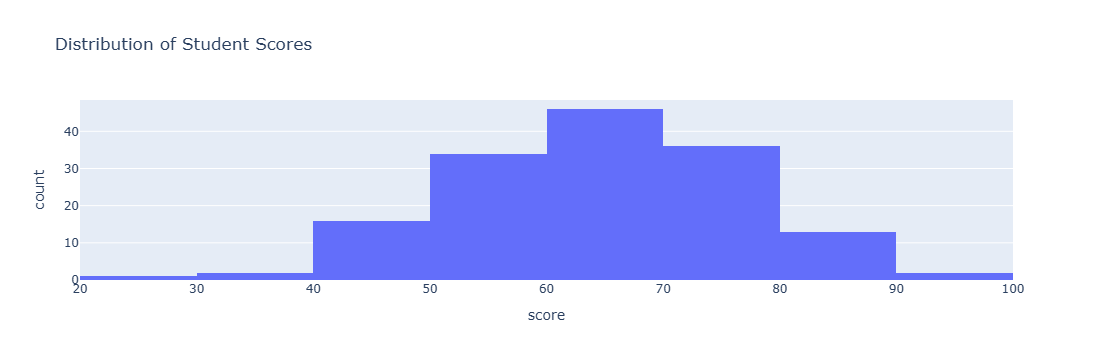

In [12]:
fig1 = px.histogram(
    df,
    x="score",
    nbins=12,
    title="Distribution of Student Scores"
)

fig1.show()

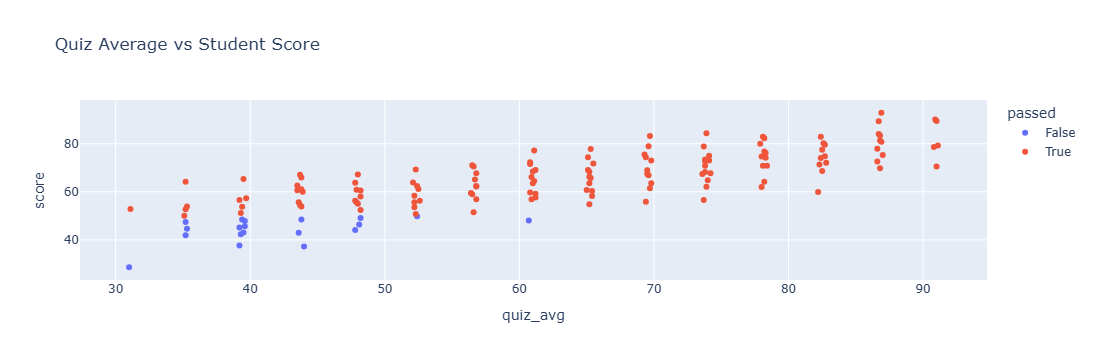

In [13]:
df["passed"] = df["score"] >= 50

fig2 = px.scatter(
    df,
    x="quiz_avg",
    y="score",
    color="passed",
    hover_name="name",
    title="Quiz Average vs Student Score"
)

fig2.show()

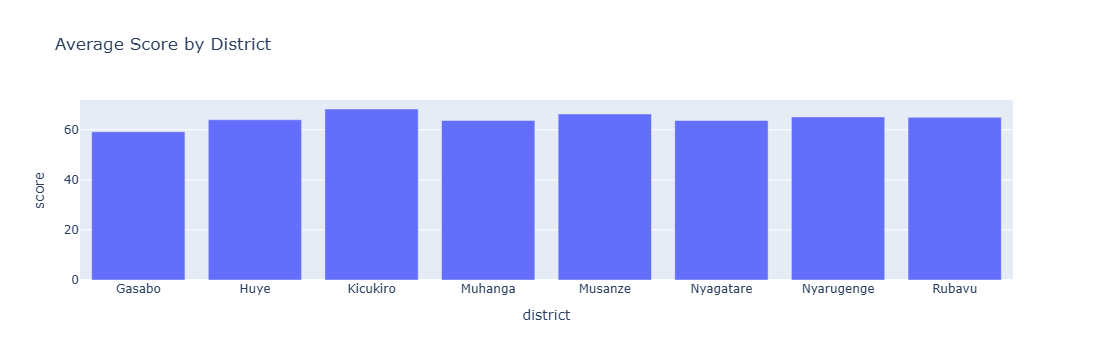

In [14]:
district_avg = df.groupby("district", as_index=False)["score"].mean()

fig3 = px.bar(
    district_avg,
    x="district",
    y="score",
    title="Average Score by District"
)

fig3.show()

In [15]:
fig2.write_html("Week10_Big Data/class_dashboard.html")

print("Dashboard saved successfully!")

Dashboard saved successfully!


In [18]:
import webbrowser

dashboard_path = os.path.abspath("Week10_Big Data/class_dashboard.html")
webbrowser.open("file:///" + dashboard_path.replace("\\", "/"))

True

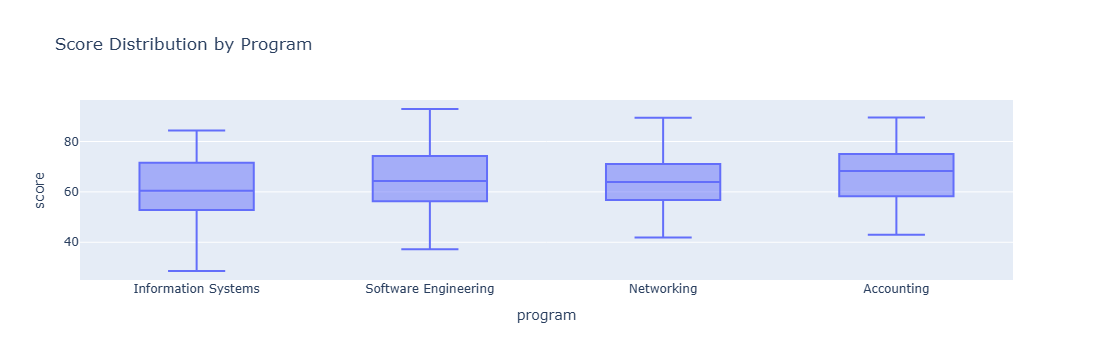

In [19]:
fig4 = px.box(
    df,
    x="program",
    y="score",
    title="Score Distribution by Program"
)

fig4.show()

# PART 6: MODEL CARD

## 1. Model Purpose
The purpose of this project is to predict students' academic scores and classify students as pass or fail based on their academic performance.

## 2. Features Used
The main features used are:
- Quiz Average (`quiz_avg`)
- Assignments Average (`assignments_avg`)
- Attendance Percentage (`attendance_pct`)

The program category was also tested to see whether it improved prediction performance.

## 3. Model Performance

**Linear Regression**
- Mean Absolute Error (MAE): 3.33
- R² Score: 0.8866
- The model explains approximately 88.66% of the variation in student scores.

**Logistic Regression**
- Accuracy: 89.47%
- All-Pass Baseline Accuracy: 89.47%
- The model achieved the same accuracy as the all-pass baseline and did not improve on it.

## 4. Feature Comparison
- Quiz Only R²: 0.6242
- All Numeric Features R²: 0.8866
- Numeric Features + Program R²: 0.8804

The three numeric features produced the best result.

## 5. Risks and Limitations
- The dataset contains only 150 students, so it may not represent all students.
- Predictions are estimates and may not always be accurate.
- The pass/fail model has limited ability to identify failing students.
- Other factors that affect academic performance may not be included in the dataset.
- The model should not be used as the only basis for important academic decisions.